## Libraries

In [1]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

## Import Dataset

In [10]:
df = pd.read_csv('../../Dataset/store_customers.csv', encoding='latin-1')
X = df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].dropna()
print(X.head())

    Age  Annual Income (k$)  Spending Score (1-100)
0  39.0                59.9                    58.0
1  34.0                48.4                    37.0
2  40.0                70.5                    26.0
3  47.0                81.1                    30.0
4  33.0                42.1                    58.0


## Standardize

In [11]:
scale = StandardScaler()
X_scale = scale.fit_transform(X)
print(X_scale)

[[ 0.0030337   0.0895807   0.76675619]
 [-0.37011189 -0.31197816 -0.27817225]
 [ 0.07766282  0.45971321 -0.82551571]
 ...
 [ 0.52543753  0.36194236 -0.82551571]
 [-0.8178866  -0.40625719  0.81651468]
 [ 2.09264902  1.76216063 -2.06947814]]


## Find the eps

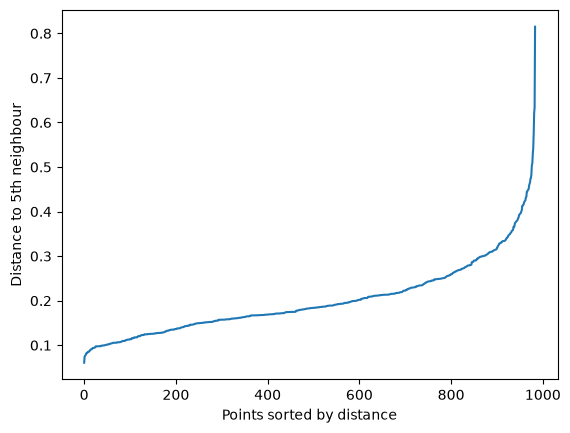

In [12]:
k = 5
nn = NearestNeighbors(n_neighbors=k).fit(X_scale)
distance, _ = nn.kneighbors(X_scale)
plt.plot(np.sort(distance[:, -1]))
plt.ylabel(f"Distance to {k}th neighbour")
plt.xlabel("Points sorted by distance")
plt.show()

## Scale the Graph image

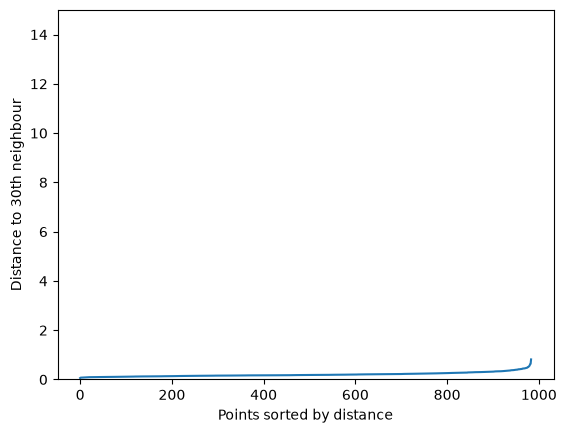

In [13]:
k_dist = np.sort(distance[:, -1])

plt.plot(k_dist)
plt.ylim(0, 15)
plt.ylabel("Distance to 30th neighbour")
plt.xlabel("Points sorted by distance")
plt.show()

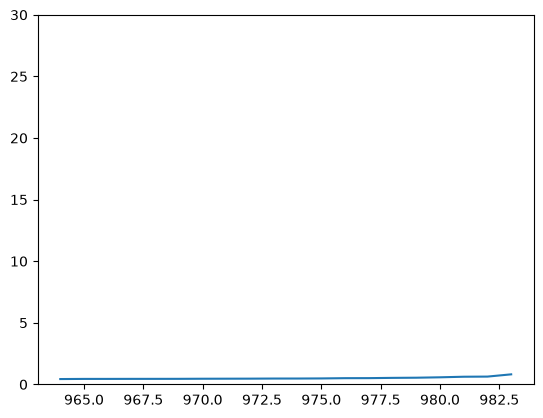

In [14]:
n = len(k_dist)
plt.plot(range(int(n * 0.98), n), k_dist[int(n * 0.98):])
plt.ylim(0, 30)
plt.show()

In [15]:
print(np.percentile(k_dist, [90, 95, 98, 99, 99.5, 99.9]))

[0.3090834  0.35760801 0.43223639 0.47423868 0.53018782 0.6357685 ]


## Train Model

In [19]:
for min_s in [5, 8, 10, 12]:
    for eps in [0.15, 0.2, 0.25, 0.3, 0.35]:
        labels = DBSCAN(eps=eps, min_samples=min_s).fit_predict(X_scale)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = (labels == -1).sum()
        print(f"min_samples={min_s}, eps={eps}: clusters={n_clusters}, noise={n_noise}")

min_samples=5, eps=0.15: clusters=19, noise=574
min_samples=5, eps=0.2: clusters=14, noise=221
min_samples=5, eps=0.25: clusters=3, noise=111
min_samples=5, eps=0.3: clusters=2, noise=47
min_samples=5, eps=0.35: clusters=1, noise=19
min_samples=8, eps=0.15: clusters=10, noise=762
min_samples=8, eps=0.2: clusters=12, noise=400
min_samples=8, eps=0.25: clusters=3, noise=175
min_samples=8, eps=0.3: clusters=3, noise=84
min_samples=8, eps=0.35: clusters=2, noise=43
min_samples=10, eps=0.15: clusters=5, noise=904
min_samples=10, eps=0.2: clusters=6, noise=532
min_samples=10, eps=0.25: clusters=3, noise=229
min_samples=10, eps=0.3: clusters=3, noise=119
min_samples=10, eps=0.35: clusters=2, noise=54
min_samples=12, eps=0.15: clusters=2, noise=944
min_samples=12, eps=0.2: clusters=4, noise=606
min_samples=12, eps=0.25: clusters=5, noise=286
min_samples=12, eps=0.3: clusters=2, noise=140
min_samples=12, eps=0.35: clusters=2, noise=56


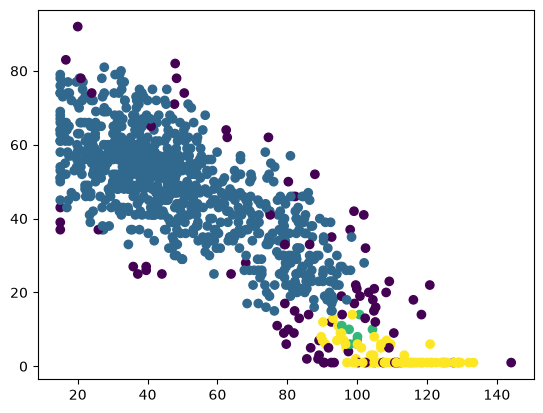

In [ ]:
labels = DBSCAN(eps=0.3, min_samples=8).fit_predict(X_scale)  
plt.scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"], c=labels, cmap="viridis")
plt.show()